### 🌾**Deep Learning for Well-watered & Drought Stress Maize Images**

**2D CNN Model**

Input Images Source: https://zenodo.org/records/10991581

Description
- Custom trained 2D CNN model for maize images water stress classification (i.e., Drought vs Watered)


---
Resources:
1. TensorFlow Autotuning
https://www.tensorflow.org/guide/data_performance

In [1]:
import numpy as np
from pathlib import Path
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input,
                                    RandomFlip, Activation, BatchNormalization, GlobalAveragePooling2D)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
# from google.colab import drive - uncomment if use google colab
from pathlib import Path
import time
import math

# Set random seed for reproducibility
SEED_SIZE = 42
keras.utils.set_random_seed(SEED_SIZE)

# Restart Keras session to clear previous instances
keras.backend.clear_session()

# Initialize Seaborn theme
sns.set_theme(style='darkgrid')

plt.rcParams.update({
    'font.family': 'monospace',
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})

In [2]:
"""---------------------------------
Connect to Google Drive -- Uncomment if run on Google Drive
------------------------------------"""

# drive.mount('/content/drive')
# DATA_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/DL_assignment/maize_watered_drought_sorted")

'---------------------------------\nConnect to Google Drive -- Uncomment if run on Google Drive\n------------------------------------'

In [3]:
"""---------------------------------
Connect to Folder Path Containing Train, Test & Validation Images
------------------------------------"""
DATA_ROOT = Path("maize_watered_drought_sorted")

In [4]:
"""---------------------------------
Load train-test-val data sets
------------------------------------"""

BATCH_SIZE = 64
IMAGE_SIZE = (168, 224)

# Predefined classes to ensure consistency in encoding during model training & validation
CLASSES = ['Drought_Trial001_2', 'Watered_Trial001_1']

train_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "train",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=True,
    seed=SEED_SIZE
)

validation_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "validation",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=False,

)

test_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "test",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    shuffle=False
)

Found 3678 files belonging to 2 classes.
Found 788 files belonging to 2 classes.
Found 789 files belonging to 2 classes.


In [5]:
"""---------------------------------
Dataset Normalization & Optimization of TensorFlow Pipeline
------------------------------------"""

AUTOTUNE = tf.data.AUTOTUNE

validation_ds = validation_ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)
validation_ds = validation_ds.batch(BATCH_SIZE)
validation_ds = validation_ds.cache()
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.cache()
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

train_ds = train_ds.cache()
train_ds = train_ds.shuffle(2000, seed=SEED_SIZE)
train_ds = train_ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)

In [6]:
"""---------------------------------
Model 1 - CNN
------------------------------------"""
trainingtime_start = time.perf_counter() # Start time counter

# Initialization
FILTER_1 = 32
FILTER_2 = 64
FILTER_3 = 128
KERNEL_SIZE = (3,3)

tf.keras.backend.clear_session()

CNN_model = Sequential([
    Input(shape=(168, 224, 3)),

    Conv2D(FILTER_1, KERNEL_SIZE, padding = 'same', kernel_initializer='he_normal'),
    Activation('relu'),
    MaxPooling2D(2, 2),

    Conv2D(FILTER_2, KERNEL_SIZE, padding = 'same', kernel_initializer='he_normal'),
    Activation('relu'),
    MaxPooling2D(2, 2),

    Conv2D(FILTER_3, KERNEL_SIZE, padding = 'same', kernel_initializer='he_normal'),
    Activation('relu'),
    MaxPooling2D(2, 2),
    
    Flatten(),
    
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid', dtype='float32',  kernel_initializer='glorot_uniform')

], name='CNN_classifier')

In [7]:
"""---------------------------------
Model Fitting
------------------------------------"""

CNN_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss = 'binary_crossentropy', 
    metrics = ['accuracy']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5,          
    restore_best_weights=True
)

reduceLRonplateau = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,         
        patience=3,         
        min_lr=1e-6,
        verbose=1
    )

CNN_history = CNN_model.fit(train_ds,
              validation_data = validation_ds,
              epochs = 30, 
              callbacks=[early_stopping, reduceLRonplateau])

print(CNN_history.history)

# Compute training time
trainingtime_end = time.perf_counter()
training_duration = trainingtime_end - trainingtime_start

print(f"Training Time: {training_duration:.4f} seconds")

Epoch 1/30


c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 ━━━━━━━━━━━━━━━━━━━━ 35s 534ms/step - accuracy: 0.4891 - loss: 0.7414 - val_accuracy: 0.5063 - val_loss: 0.7087 - learning_rate: 1.0000e-05
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 35s 474ms/step - accuracy: 0.5068 - loss: 0.7050 - val_accuracy: 0.4937 - val_loss: 0.7038 - learning_rate: 1.0000e-05
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 30s 516ms/step - accuracy: 0.4951 - loss: 0.7040 - val_accuracy: 0.4911 - val_loss: 0.7040 - learning_rate: 1.0000e-05
Epoch 4/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 30s 517ms/step - accuracy: 0.4872 - loss: 0.7033 - val_accuracy: 0.5076 - val_loss: 0.7028 - learning_rate: 1.0000e-05
Epoch 5/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 32s 557ms/step - accuracy: 0.5003 - loss: 0.7026 - val_accuracy: 0.5127 - val_loss: 0.7022 - learning_rate: 1.0000e-05
Epoch 6/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 32s 545ms/step - accuracy: 0.5068 - loss: 0.7019 - val_accuracy: 0.5063 - val_loss: 0.7017 - learning_rate: 1.0000e-05
Epoch 7/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 31s 531ms/step - accuracy: 0.50

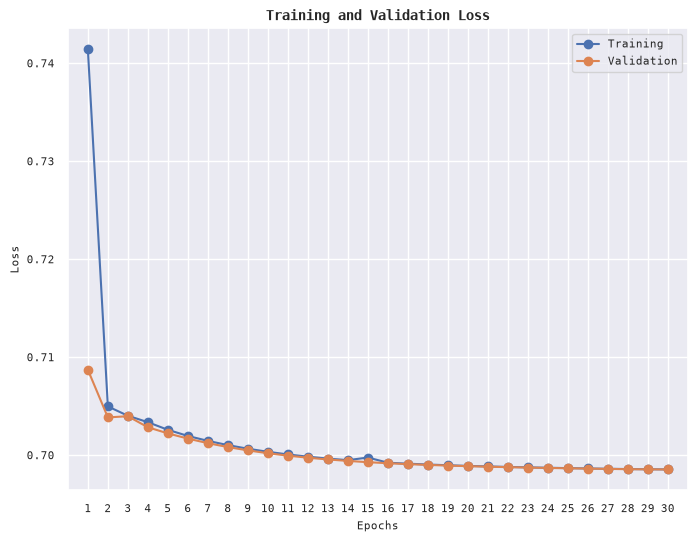

In [8]:
"""---------------------------------
Generating Epochs vs Error Plot
------------------------------------"""
x_range = range(1, len(CNN_history.history['loss']) + 1)
plt.figure(figsize=(8,6))

plt.plot(x_range, CNN_history.history['loss'], label='Training', marker='o')
plt.plot(x_range, CNN_history.history['val_loss'], label='Validation', marker='o')

plt.xlim(0, len(CNN_history.history['loss'])+1)
plt.xticks(range(1, len(CNN_history.history['loss'])+1))
plt.xlabel('Epochs', fontsize=8)
plt.ylabel('Loss', fontsize=8)
plt.grid(True, linestyle='-', linewidth=1)
plt.title('Training and Validation Loss', fontsize=10, fontweight='bold')
plt.legend(fontsize=8)
plt.show()


Accuracy: 0.507
precision: 0.0
recall: 0.0
f1: 0.0
Confusion Matrix:
[[400   0]
 [389   0]]


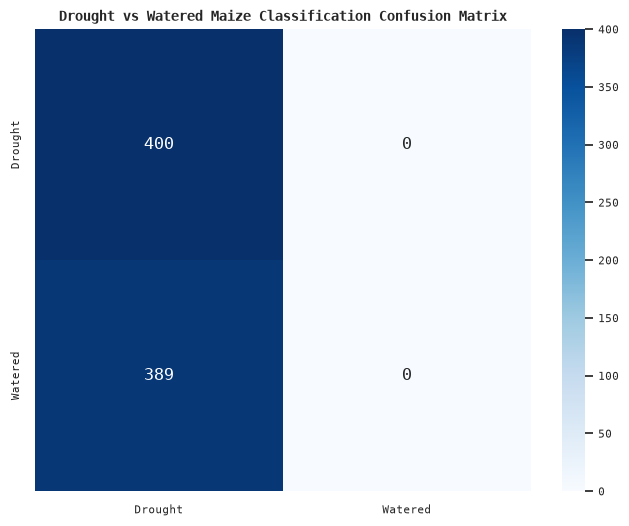

In [9]:
"""---------------------------------
Summary Results
------------------------------------"""

test_ypred_raw = CNN_model.predict(test_ds, verbose=0).flatten()
test_ytrue = np.concatenate([y.numpy() for _, y in test_ds], axis=0).flatten().astype(int)
test_ypred = (test_ypred_raw >= 0.5).astype(int)

# Extract ground truth labels & convert to 1D numpy array of intergers
test_conmat = confusion_matrix(test_ytrue, test_ypred)

# Compute for accuracy, precision, recall and F1 score
accuracy = accuracy_score(test_ytrue, test_ypred)
precision = precision_score(test_ytrue, test_ypred, zero_division=0)
recall = recall_score(test_ytrue, test_ypred, zero_division=0)
f1 = f1_score(test_ytrue, test_ypred, zero_division=0)

print(f'Accuracy: {round((accuracy),4)}')
print(f'precision: {round((precision),4)}')
print(f'recall: {round((recall),4)}')
print(f'f1: {round((f1),4)}')
print(f'Confusion Matrix:\n{test_conmat}')

# Define class names for Confusion Matrix
class_names = ['Drought', 'Watered'] 

# Generate Confusion Matrix Chart
plt.figure(figsize=(8, 6))
sns.heatmap(test_conmat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Drought vs Watered Maize Classification Confusion Matrix", fontsize=10, fontweight='bold')
plt.show()

In [10]:
CNN_model.summary()

Model: "CNN_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 168, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 168, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 84, 112, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 84, 112, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 84, 112, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 42, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 42, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 42, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 21, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 75264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     4,816,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,730,821 (56.19 MB)

 Trainable params: 4,910,273 (18.73 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,820,548 (37.46 MB)